# [ 과제3 ] 특성 공학(Feature Engineering) 파이프라인 구현 및 성능 비교 실험

소프트웨어대학 컴퓨터공학과 빅데이터분석 01분반 - 2342803 문서영
### 선택한 데이터셋 - ① Titanic Dataset

- 목적: 생존 여부 예측 (Classification)
- 장점:
    - 결측치 포함
    - 범주형 + 수치형 혼합
    - Feature Engineering 연습에 매우 적합
- Kaggle:
    - Titanic - Machine Learning from Disaster
- 링크:
    - https://www.kaggle.com/competitions/titanic/data

### STEP 1. Google Colab 환경 설정

##### 1. 실행 환경 설정

In [1]:

# ==========================================
# Big Data Analysis - Feature Engineering
# STEP 1. Environment Setup
# ==========================================

import sys
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 머신러닝 라이브러리
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    OneHotEncoder,
    LabelEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_classif

# 시각화 설정
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

# 출력 설정
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 120)

print("=" * 50)
print("Big Data Analysis - Feature Engineering")
print("=" * 50)

print(f"Python Version: {sys.version}")
print(f"Pandas Version: {pd.__version__}")
print(f"NumPy Version: {np.__version__}")
print(f"Scikit-learn Version: {sklearn.__version__}")

print("\n환경 설정 완료!")


Big Data Analysis - Feature Engineering
Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pandas Version: 2.2.3
NumPy Version: 2.4.6
Scikit-learn Version: 1.6.1

환경 설정 완료!


### STEP 2. Titanic 데이터 수집 및 로드

#### 2-1. Titanic 데이터 수집 및 로드 - ( Titanic Dataset Information )

In [2]:

# ==========================================
# STEP 2-1. Titanic Dataset Loading
# ==========================================

# 공개 Titanic 데이터 다운로드
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

# 데이터 기본 정보
print("=" * 60)
print("TITANIC DATASET INFORMATION")
print("=" * 60)

print(f"\n데이터 Shape: {df.shape}")
print(f"전체 데이터 수: {df.shape[0]}개")
print(f"전체 변수 수: {df.shape[1]}개")

print("\n[컬럼 목록]")
print(df.columns.tolist())

print("\n[데이터 상위 5개]")
display(df.head())

print("\n[데이터 기본 정보]")
df.info()

print("\n[타겟 변수 분포]")
print(df['Survived'].value_counts())

print("\n[타겟 변수 비율]")
print(df['Survived'].value_counts(normalize=True) * 100)


TITANIC DATASET INFORMATION

데이터 Shape: (891, 12)
전체 데이터 수: 891개
전체 변수 수: 12개

[컬럼 목록]
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

[데이터 상위 5개]


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



[데이터 기본 정보]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

[타겟 변수 분포]
Survived
0    549
1    342
Name: count, dtype: int64

[타겟 변수 비율]
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


#### 2-2. Titanic Dataset 소개 및 컬럼 설명

본 프로젝트에서는 Kaggle의 Titanic Dataset을 활용하여 승객의 생존 여부를 예측하는 이진 분류 문제를 수행하였다.

해당 데이터셋은 실제 타이타닉호 탑승객 정보를 바탕으로 구성되어 있으며, 수치형 변수와 범주형 변수가 함께 포함되어 있다. 또한 Age, Cabin, Embarked 등의 변수에 결측치가 존재하기 때문에 다양한 데이터 전처리 및 특성 공학 기법을 비교하기에 적합하다.

- 데이터 출처: Kaggle Titanic - Machine Learning from Disaster
- 데이터 크기: 891개 행 × 12개 열
- 예측 목표: 승객의 생존 여부
- 타겟 변수: Survived
- 문제 유형: 지도학습 기반 이진 분류(Classification)

##### 데이터 컬럼 설명

| 컬럼명 | 설명 | 데이터 유형 |
|---|---|---|
| PassengerId | 승객 고유 식별 번호 | 수치형 |
| Survived | 생존 여부 (0: 사망, 1: 생존) | 타겟 변수 |
| Pclass | 객실 등급 (1, 2, 3등급) | 범주형 성격의 정수형 |
| Name | 승객 이름 | 범주형 |
| Sex | 승객 성별 | 범주형 |
| Age | 승객 나이 | 수치형 |
| SibSp | 함께 탑승한 형제자매 및 배우자 수 | 수치형 |
| Parch | 함께 탑승한 부모 및 자녀 수 | 수치형 |
| Ticket | 티켓 번호 | 범주형 |
| Fare | 승객 운임 | 수치형 |
| Cabin | 객실 번호 | 범주형 |
| Embarked | 승선 항구 | 범주형 |

##### 타겟 변수 정의

본 프로젝트의 예측 대상은 Survived 변수이다.

- 0: 사망
- 1: 생존

전체 891명 중 사망자는 549명(61.62%), 생존자는 342명(38.38%)으로 나타났다. 따라서 타겟 변수의 분포가 완전히 균형 잡혀 있지는 않으며, 모델 평가 시 Accuracy뿐만 아니라 Precision, Recall, F1-score, ROC-AUC를 함께 활용하였다.

### STEP 3. 탐색적 데이터 분석 (EDA)

#### 3-1. 결측치 분석

##### Missing Value Analysis

MISSING VALUE ANALYSIS


,Missing Count,Missing Ratio (%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


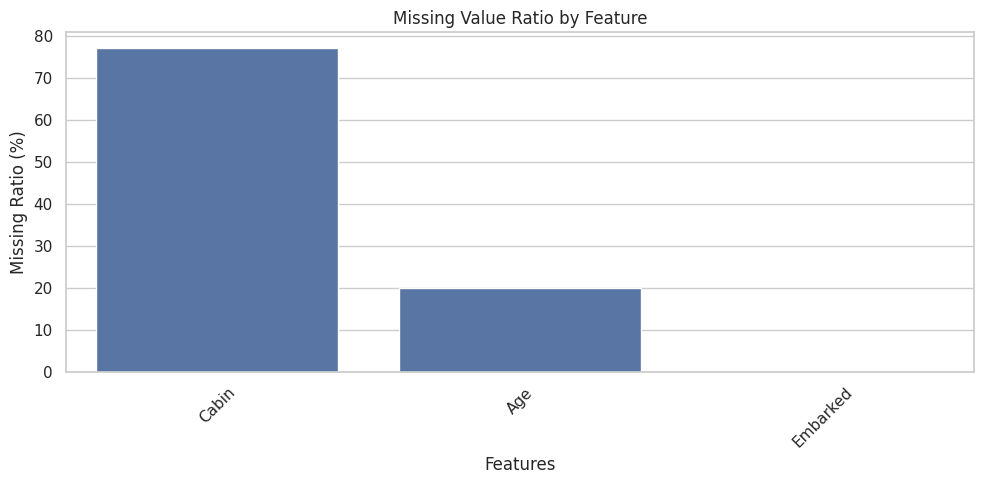

In [3]:

# ==========================================
# STEP 3-1. Missing Value Analysis
# ==========================================

# 결측치 개수 및 비율 계산
missing_count = df.isnull().sum()
missing_ratio = (df.isnull().mean() * 100).round(2)

missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Ratio (%)': missing_ratio
})

missing_df = missing_df[missing_df['Missing Count'] > 0]
missing_df = missing_df.sort_values(
    by='Missing Ratio (%)',
    ascending=False
)

print("=" * 60)
print("MISSING VALUE ANALYSIS")
print("=" * 60)

display(missing_df)

# 결측치 시각화
plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_df.index,
    y=missing_df['Missing Ratio (%)']
)

plt.title('Missing Value Ratio by Feature')
plt.xlabel('Features')
plt.ylabel('Missing Ratio (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


##### 결과 해석 - 결측치 분석

결측치 분석 결과, Cabin 컬럼에서 687개(77.10%)의 결측치가 확인되었으며, Age 컬럼에서는 177개(19.87%), Embarked 컬럼에서는 2개(0.22%)의 결측치가 나타났다.

Cabin은 결측 비율이 매우 높으므로 기존 값을 그대로 활용하기 어렵지만, 객실 정보의 존재 여부가 생존 예측에 영향을 줄 가능성을 고려하여 HasCabin이라는 파생 변수를 생성하였다.

Age는 평균 또는 중앙값 등의 대체 방법을 비교하고, Embarked는 최빈값을 활용하여 결측치를 처리하고자 한다.

#### 3-2. 이상치 탐색 및 데이터 분포 시각화

##### Outlier Analysis

[IQR Outlier Analysis]


,Feature,Lower Bound,Upper Bound,Outlier Count
0,Age,-6.6875,64.8125,11
1,SibSp,-1.5000,2.5000,46
2,Parch,0.0000,0.0000,213
3,Fare,-26.7240,65.6344,116


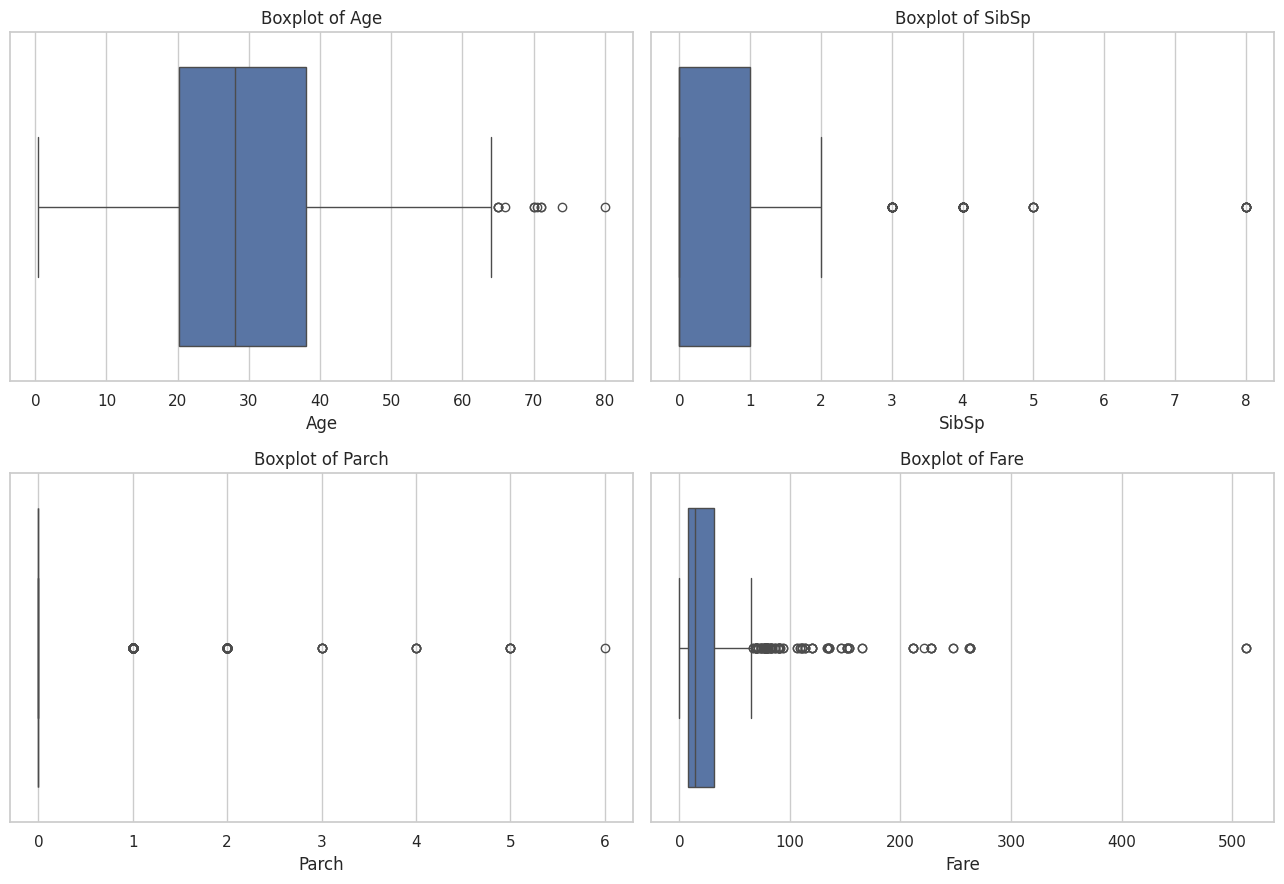

In [4]:

# ==========================================
# STEP 3-2. Outlier Analysis
# ==========================================

numeric_cols = ['Age', 'SibSp', 'Parch', 'Fare']

# IQR 방식으로 이상치 탐색
outlier_results = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    outlier_results.append({
        'Feature': col,
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Outlier Count': len(outliers)
    })

outlier_df = pd.DataFrame(outlier_results)

print("[IQR Outlier Analysis]")
display(outlier_df)

# Boxplot
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(axes.flatten(), numeric_cols):
    sns.boxplot(data=df, x=col, ax=ax)
    ax.set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()


##### 결과 해석 - 이상치 탐색 및 데이터 분포 시각화


IQR 방법을 이용한 이상치 분석 결과, Age에서 11개, SibSp에서 46개, Parch에서 213개, Fare에서 116개의 이상치가 확인되었다.

특히 Fare와 Parch에서 상대적으로 많은 이상치가 나타났다. 그러나 이러한 값들은 실제 승객의 운임이나 가족 구성 규모를 반영하는 유의미한 정보일 수 있다.

따라서 이상치를 무조건 제거하지 않고 유지하여 모델 학습에 활용하며, RobustScaler와 같은 스케일링 기법을 통해 이상치의 영향을 비교하고자 한다.

#### 3-3. 변수 분포 및 상관관계 / 범주형 변수별 생존율 분석

##### ① 변수 분포 및 상관관계 분석

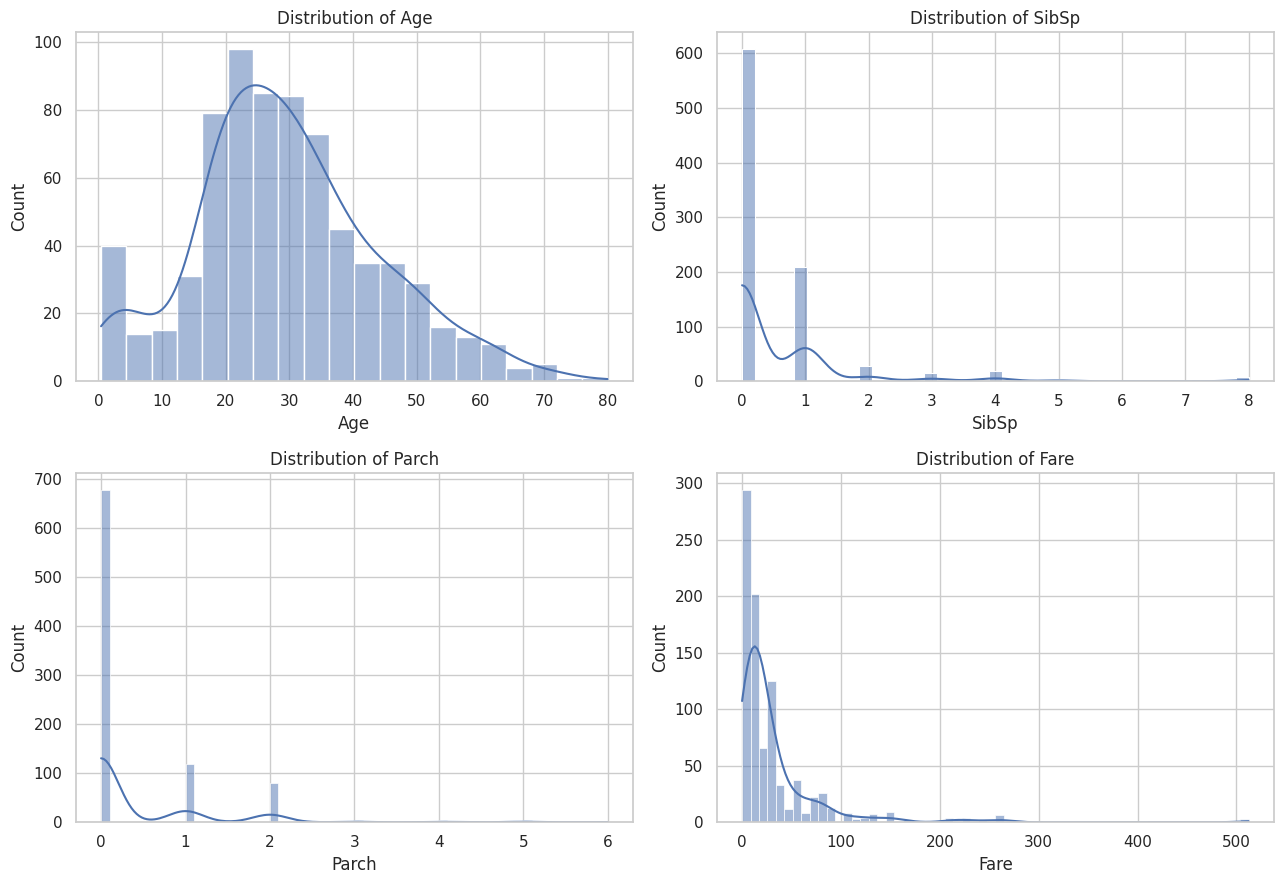

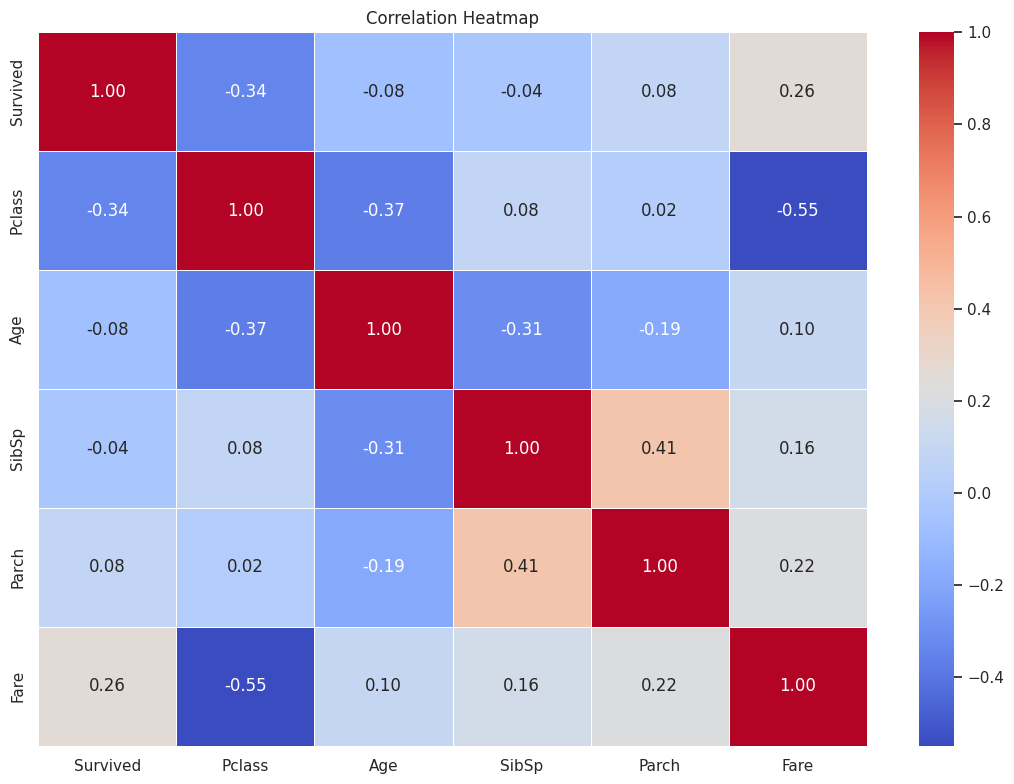

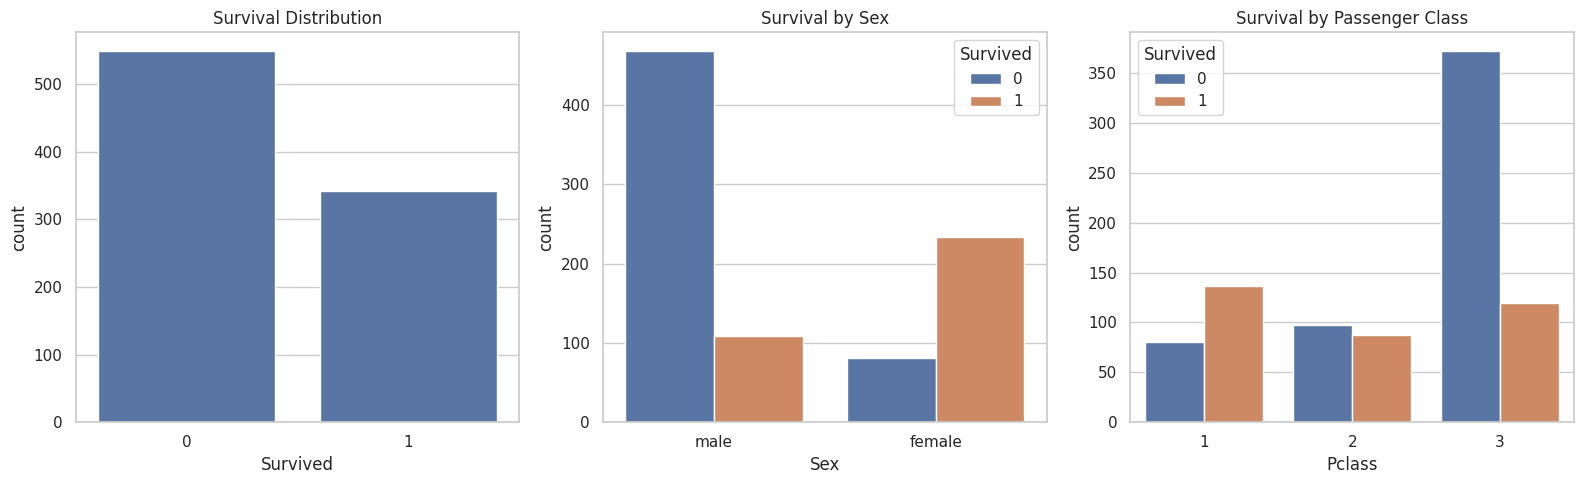

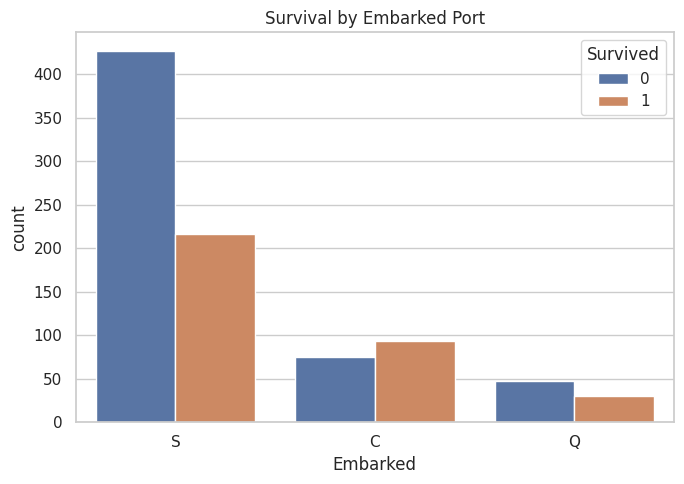

In [5]:

# ==========================================
# STEP 3-3. Distribution & Correlation
# ==========================================

# 1. Histogram
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(axes.flatten(), numeric_cols):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=ax
    )
    ax.set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()


# 2. Correlation Heatmap
plt.figure(figsize=(11, 8))

correlation = df[
    ['Survived', 'Pclass', 'Age', 'SibSp',
     'Parch', 'Fare']
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


# 3. Target Variable Countplot
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.countplot(data=df, x='Survived', ax=axes[0])
axes[0].set_title('Survival Distribution')

sns.countplot(data=df, x='Sex', hue='Survived', ax=axes[1])
axes[1].set_title('Survival by Sex')

sns.countplot(data=df, x='Pclass', hue='Survived', ax=axes[2])
axes[2].set_title('Survival by Passenger Class')

plt.tight_layout()
plt.show()


# 4. Embarked Distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Embarked', hue='Survived')

plt.title('Survival by Embarked Port')
plt.tight_layout()
plt.show()


##### ② 범주형 변수별 생존율 분석


[Sex별 생존율]


,Total Passengers,Survivors,Survival Rate
Sex,,,
female,314,233,74.20
male,577,109,18.89



[Pclass별 생존율]


,Total Passengers,Survivors,Survival Rate
Pclass,,,
1,216,136,62.96
2,184,87,47.28
3,491,119,24.24



[Embarked별 생존율]


,Total Passengers,Survivors,Survival Rate
Embarked,,,
C,168,93,55.36
Q,77,30,38.96
S,644,217,33.70


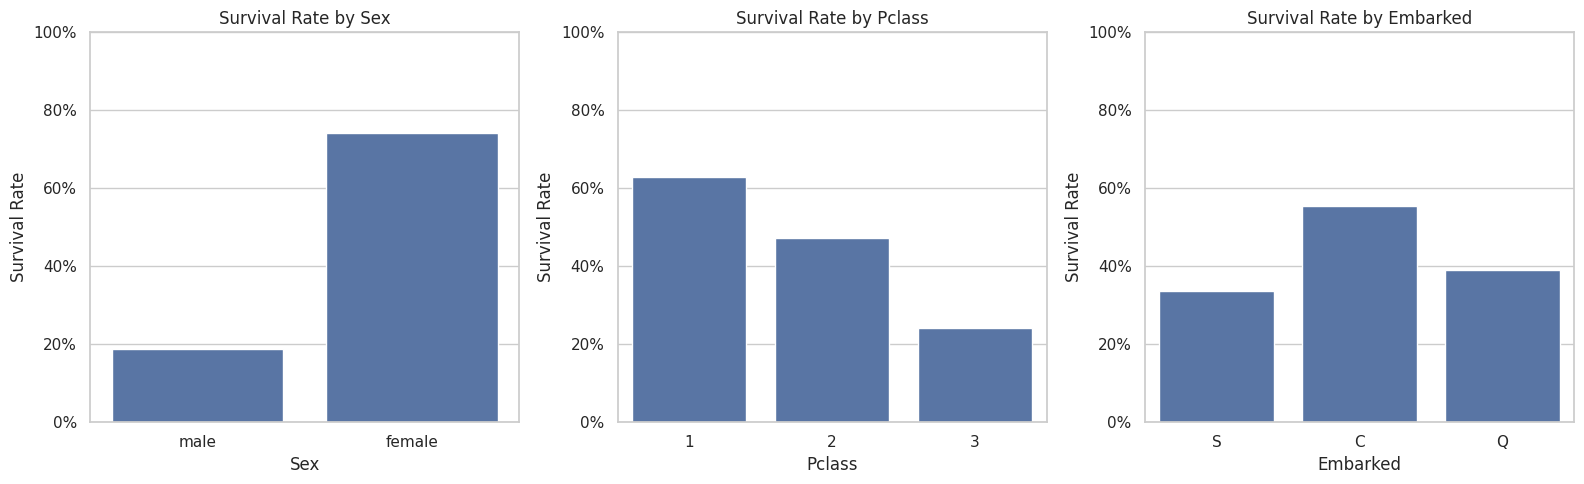

In [6]:

# ==========================================
# STEP 3-3. Survival Rate Analysis
# ==========================================

# 범주형 변수별 생존율 계산
categorical_cols = ['Sex', 'Pclass', 'Embarked']

for col in categorical_cols:

    survival_rate = (
        df.groupby(col, observed=False)['Survived']
        .agg(['count', 'sum', 'mean'])
    )

    survival_rate.columns = [
        'Total Passengers',
        'Survivors',
        'Survival Rate'
    ]

    survival_rate['Survival Rate'] *= 100

    print(f"\n[{col}별 생존율]")
    display(survival_rate.round(2))


# 생존율 시각화
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, categorical_cols):

    sns.barplot(
        data=df,
        x=col,
        y='Survived',
        errorbar=None,
        ax=ax
    )

    ax.set_title(f'Survival Rate by {col}')
    ax.set_ylabel('Survival Rate')
    ax.set_ylim(0, 1)

    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda y, _: f'{y:.0%}')
    )

plt.tight_layout()
plt.show()


##### 결과 해석 - 타겟 변수 및 주요 변수 분석

전체 승객 891명 중 사망자는 549명(61.62%), 생존자는 342명(38.38%)으로 나타났다.

성별에 따른 생존율을 분석한 결과, 여성은 약 74.20%, 남성은 약 18.89%로 여성의 생존율이 훨씬 높게 나타났다.

객실 등급별 생존율은 1등급 약 62.96%, 2등급 약 47.28%, 3등급 약 24.24%로 나타났다. 이를 통해 성별과 객실 등급이 생존 여부와 관련성이 높은 변수임을 확인할 수 있었다.

이러한 분석 결과를 바탕으로 성별, 객실 등급 등의 변수를 모델 학습에 활용하고, 이후 Feature Engineering을 통해 추가적인 예측 정보를 생성하고자 한다.

### STEP 4. Feature Engineering (특성 공학)

#### 4-1. 파생 변수 생성

In [7]:

# ==========================================
# STEP 4-1. Feature Engineering
# ==========================================

# 원본 데이터 보존
df_fe = df.copy()

# 1. FamilySize: 전체 가족 구성원 수
df_fe['FamilySize'] = (
    df_fe['SibSp'] + df_fe['Parch'] + 1
)

# 2. IsAlone: 혼자 탑승했는지 여부
df_fe['IsAlone'] = (
    df_fe['FamilySize'] == 1
).astype(int)

# 3. FarePerPerson: 1인당 운임
df_fe['FarePerPerson'] = (
    df_fe['Fare'] / df_fe['FamilySize']
)

# 4. Title: 이름에서 호칭 추출
df_fe['Title'] = (
    df_fe['Name']
    .str.extract(r',\s*([^.]*)\.', expand=False)
    .str.strip()
)

# 희귀 호칭 통합
df_fe['Title'] = df_fe['Title'].replace({
    'Mlle': 'Miss',
    'Ms': 'Miss',
    'Mme': 'Mrs'
})

common_titles = [
    'Mr', 'Mrs', 'Miss', 'Master'
]

df_fe['Title'] = df_fe['Title'].where(
    df_fe['Title'].isin(common_titles),
    'Rare'
)

# 5. AgeGroup: 연령대 구분
df_fe['AgeGroup'] = pd.cut(
    df_fe['Age'],
    bins=[0, 12, 19, 35, 60, float('inf')],
    labels=[
        'Child',
        'Teenager',
        'Young Adult',
        'Adult',
        'Senior'
    ],
    include_lowest=True
)

# 6. HasCabin: 객실 정보 보유 여부
df_fe['HasCabin'] = (
    df_fe['Cabin'].notna()
).astype(int)


# 생성 결과 확인
new_features = [
    'FamilySize',
    'IsAlone',
    'FarePerPerson',
    'Title',
    'AgeGroup',
    'HasCabin'
]

print("=" * 60)
print("FEATURE ENGINEERING RESULTS")
print("=" * 60)

display(df_fe[new_features].head(10))

print("\n[파생 변수 기본 통계]")
display(df_fe[new_features].describe(include='all'))

print("\n[파생 변수 결측치]")
display(df_fe[new_features].isnull().sum())


FEATURE ENGINEERING RESULTS


,FamilySize,IsAlone,FarePerPerson,Title,AgeGroup,HasCabin
0,2,0,3.62500,Mr,Young Adult,0
1,2,0,35.64165,Mrs,Adult,1
2,1,1,7.92500,Miss,Young Adult,0
3,2,0,26.55000,Mrs,Young Adult,1
4,1,1,8.05000,Mr,Young Adult,0
5,1,1,8.45830,Mr,NaN,0
6,1,1,51.86250,Mr,Adult,1
7,5,0,4.21500,Master,Child,0
8,3,0,3.71110,Mrs,Young Adult,0
9,2,0,15.03540,Mrs,Teenager,0



[파생 변수 기본 통계]


,FamilySize,IsAlone,FarePerPerson,Title,AgeGroup,HasCabin
count,891.000000,891.000000,891.000000,891,714,891.000000
unique,NaN,NaN,NaN,5,5,NaN
top,NaN,NaN,NaN,Mr,Young Adult,NaN
freq,NaN,NaN,NaN,517,333,NaN
mean,1.904602,0.602694,19.916375,NaN,NaN,0.228956
std,1.613459,0.489615,35.841257,NaN,NaN,0.420397
min,1.000000,0.000000,0.000000,NaN,NaN,0.000000
25%,1.000000,0.000000,7.250000,NaN,NaN,0.000000
50%,1.000000,1.000000,8.300000,NaN,NaN,0.000000
75%,2.000000,1.000000,23.666667,NaN,NaN,0.000000



[파생 변수 결측치]


,0
FamilySize,0
IsAlone,0
FarePerPerson,0
Title,0
AgeGroup,177
HasCabin,0


#### 4-2. 학습 데이터와 테스트 데이터 분리

In [8]:

# ==========================================
# STEP 4-2. Train-Test Split
# ==========================================

from sklearn.model_selection import train_test_split

# 예측에 사용할 특성 선택
# AgeGroup은 나이를 구간화한 파생변수로 생성하였다.
# 다만 모델에서는 원본 Age와의 정보 중복 가능성 및
# 결측치 처리의 일관성을 고려하여 이번 실험의 입력 특성에서는 제외하였다.
feature_cols = [
    'Pclass',
    'Sex',
    'Age',
    'SibSp',
    'Parch',
    'Fare',
    'Embarked',
    'FamilySize',
    'IsAlone',
    'FarePerPerson',
    'Title',
    'HasCabin'
]

# 독립변수(X)와 종속변수(y) 분리
X = df_fe[feature_cols].copy()
y = df_fe['Survived'].copy()

# 학습 데이터 80%, 테스트 데이터 20%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("=" * 60)
print("TRAIN-TEST SPLIT RESULTS")
print("=" * 60)

print(f"\n전체 데이터: {len(X)}")
print(f"학습 데이터: {len(X_train)}")
print(f"테스트 데이터: {len(X_test)}")

print("\n[학습 데이터 타겟 분포]")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\n[테스트 데이터 타겟 분포]")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(2))

print("\n[학습 데이터 결측치]")
display(X_train.isnull().sum())

print("\n[테스트 데이터 결측치]")
display(X_test.isnull().sum())

print("\n데이터 분리 완료!")


TRAIN-TEST SPLIT RESULTS

전체 데이터: 891
학습 데이터: 712
테스트 데이터: 179

[학습 데이터 타겟 분포]
Survived
0    439
1    273
Name: count, dtype: int64
Survived
0    61.66
1    38.34
Name: proportion, dtype: float64

[테스트 데이터 타겟 분포]
Survived
0    110
1     69
Name: count, dtype: int64
Survived
0    61.45
1    38.55
Name: proportion, dtype: float64

[학습 데이터 결측치]


,0
Pclass,0
Sex,0
Age,137
SibSp,0
Parch,0
Fare,0
Embarked,2
FamilySize,0
IsAlone,0
FarePerPerson,0



[테스트 데이터 결측치]


,0
Pclass,0
Sex,0
Age,40
SibSp,0
Parch,0
Fare,0
Embarked,0
FamilySize,0
IsAlone,0
FarePerPerson,0



데이터 분리 완료!


### STEP 5. 실험별 전처리 파이프라인 구축 및 모델 비교

본 단계에서는 전처리 전략에 따른 머신러닝 모델의 성능 차이를 비교하기 위해 Base, Exp-1, Exp-2, Exp-3의 네 가지 실험을 구성하였다.

각 실험은 결측치 처리, 범주형 변수 인코딩, 데이터 스케일링 및 Feature Selection 적용 여부에 차이를 두었다.

| 실험 | 수치형 결측치 처리 | 인코딩 | 스케일링 | Feature Selection |
|---|---|---|---|---|
| Base | 없음 | 없음 | 없음 | 미적용 |
| Exp-1 | Mean | One-Hot | StandardScaler | 미적용 |
| Exp-2 | Median | OrdinalEncoder | MinMaxScaler | 적용 |
| Exp-3 | Most Frequent | One-Hot | RobustScaler | 적용 |

※ 모든 실험에서 범주형 변수의 결측치는 최빈값(Most Frequent)으로 처리하였으며, 표에 기재된 결측치 처리 전략은 수치형 변수에 적용한 방식이다.

**Exp-2 인코딩 방식 설명**

Exp-2에서는 OrdinalEncoder를 활용하여 범주형 변수를 정수형으로 변환하였다. OrdinalEncoder는 여러 범주형 특성을 한 번에 정수형으로 인코딩할 수 있으며, LabelEncoder와 유사한 정수형 변환 방식을 사용한다. 다만 명목형 변수에 정수형 값이 부여되면 실제로 존재하지 않는 순서 관계가 생길 수 있다는 한계가 있다.


#### 5-1. FEATURE ENGINEERING EXPERIMENT

In [9]:

# ==========================================
# STEP 5. Feature Engineering Experiments
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    OneHotEncoder,
    OrdinalEncoder
)
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ------------------------------------------
# 1. 변수 구분
# ------------------------------------------

numeric_features = [
    'Pclass', 'Age', 'SibSp', 'Parch', 'Fare',
    'FamilySize', 'IsAlone', 'FarePerPerson', 'HasCabin'
]

categorical_features = [
    'Sex', 'Embarked', 'Title'
]

# Base: 전처리 없이 학습할 수 있도록
# 결측치가 없는 수치형 변수만 사용한 기준 모델
base_features = [
    'Pclass', 'SibSp', 'Parch', 'Fare',
    'FamilySize', 'IsAlone', 'FarePerPerson', 'HasCabin'
]

# ------------------------------------------
# 2. 실험별 전처리 파이프라인
# ------------------------------------------

# Exp-1: Mean + One-Hot + Standard
exp1_numeric = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

exp1_categorical = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_exp1 = ColumnTransformer([
    ('num', exp1_numeric, numeric_features),
    ('cat', exp1_categorical, categorical_features)
])


# Exp-2: Median + Ordinal + MinMax
exp2_numeric = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

exp2_categorical = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

preprocessor_exp2 = ColumnTransformer([
    ('num', exp2_numeric, numeric_features),
    ('cat', exp2_categorical, categorical_features)
])


# Exp-3: Most Frequent + One-Hot + Robust
exp3_numeric = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('scaler', RobustScaler())
])

exp3_categorical = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_exp3 = ColumnTransformer([
    ('num', exp3_numeric, numeric_features),
    ('cat', exp3_categorical, categorical_features)
])


# ------------------------------------------
# 3. 실험 설정
# ------------------------------------------

experiments = {
    'Base': {
        'preprocessor': None,
        'feature_selection': False
    },
    'Exp-1': {
        'preprocessor': preprocessor_exp1,
        'feature_selection': False
    },
    'Exp-2': {
        'preprocessor': preprocessor_exp2,
        'feature_selection': True
    },
    'Exp-3': {
        'preprocessor': preprocessor_exp3,
        'feature_selection': True
    }
}

# ------------------------------------------
# 4. 비교 모델
# ------------------------------------------

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=3000,
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
}


# ------------------------------------------
# 5. 모델 학습 및 평가
# ------------------------------------------

results = []

for exp_name, exp_config in experiments.items():

    for model_name, model in models.items():

        steps = []

        # 전처리
        if exp_config['preprocessor'] is not None:
            steps.append((
                'preprocessor',
                exp_config['preprocessor']
            ))

        # Feature Selection
        if exp_config['feature_selection']:
            steps.append((
                'feature_selection',
                SelectKBest(
                    score_func=f_classif,
                    k=10
                )
            ))

        # 모델
        steps.append(('model', model))

        pipeline = Pipeline(steps)

        # Base는 결측치가 없는 수치형 변수만 사용
        if exp_name == 'Base':
            X_train_exp = X_train[base_features]
            X_test_exp = X_test[base_features]
        else:
            X_train_exp = X_train
            X_test_exp = X_test

        # 학습
        pipeline.fit(X_train_exp, y_train)

        # 예측
        y_pred = pipeline.predict(X_test_exp)
        y_prob = pipeline.predict_proba(X_test_exp)[:, 1]

        # 평가
        results.append({
            'Experiment': exp_name,
            'Model': model_name,
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision': precision_score(
                y_test, y_pred, zero_division=0
            ),
            'Recall': recall_score(
                y_test, y_pred, zero_division=0
            ),
            'F1-score': f1_score(
                y_test, y_pred, zero_division=0
            ),
            'ROC-AUC': roc_auc_score(y_test, y_prob)
        })

# ------------------------------------------
# 6. 결과 출력
# ------------------------------------------

results_df = pd.DataFrame(results)

print("=" * 70)
print("FEATURE ENGINEERING EXPERIMENT RESULTS")
print("=" * 70)

display(
    results_df.sort_values(
        by='F1-score',
        ascending=False
    ).round(4)
)

print("\n총 실험 수:", len(results_df))
print("실험 완료!")


FEATURE ENGINEERING EXPERIMENT RESULTS


,Experiment,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
2,Exp-1,Logistic Regression,0.8324,0.8000,0.7536,0.7761,0.8722
5,Exp-2,Random Forest,0.8045,0.7576,0.7246,0.7407,0.8343
3,Exp-1,Random Forest,0.7877,0.7183,0.7391,0.7286,0.8287
4,Exp-2,Logistic Regression,0.7709,0.7059,0.6957,0.7007,0.8403
6,Exp-3,Logistic Regression,0.7654,0.7077,0.6667,0.6866,0.8344
7,Exp-3,Random Forest,0.7542,0.6761,0.6957,0.6857,0.8179
1,Base,Random Forest,0.5866,0.4638,0.4638,0.4638,0.6311
0,Base,Logistic Regression,0.6536,0.5854,0.3478,0.4364,0.6961



총 실험 수: 8
실험 완료!


#### 5-2. 실험 결과 분석

총 4가지 실험(Base, Exp-1, Exp-2, Exp-3)과 2가지 머신러닝 모델(Logistic Regression, Random Forest)을 조합하여 총 8개의 실험을 진행하였다.

실험 결과, Exp-1의 Logistic Regression 모델이 Accuracy 0.8324, Precision 0.8000, Recall 0.7536, F1-score 0.7761, ROC-AUC 0.8722로 가장 우수한 전반적인 성능을 보였다.

Exp-2에서는 Random Forest가 F1-score 0.7407을 기록하였으며, Logistic Regression보다 높은 성능을 나타냈다. 반면 Exp-3에서는 두 모델 모두 Exp-1보다 낮은 F1-score를 기록하였다.

이를 통해 결측치 처리, 인코딩 및 스케일링 전략의 조합에 따라 모델의 예측 성능이 달라질 수 있음을 확인하였다. 특히 본 실험에서는 Mean Imputation, One-Hot Encoding, StandardScaler를 적용한 Exp-1이 가장 높은 F1-score와 ROC-AUC를 기록하였다. 다만 여러 전처리 전략을 동시에 변경하였으므로 개별 전처리 기법이 성능에 미친 영향을 독립적으로 판단하기는 어렵다.

### STEP 6. Feature Selection 효과 검증



본 단계에서는 Feature Selection이 머신러닝 모델의 예측 성능에 미치는 영향을 확인하기 위해 특성 선택 적용 전후의 성능을 비교하였다.

Exp-1, Exp-2, Exp-3의 세 가지 전처리 실험에 Logistic Regression과 Random Forest를 각각 적용하였으며, 각 실험에서 Feature Selection을 적용한 경우와 적용하지 않은 경우를 비교하였다.

특성 선택 방법으로는 SelectKBest와 f_classif를 사용하였으며, 전체 특성 중 상위 10개의 특성을 선택하도록 설정하였다.

이를 통해 불필요한 특성을 제거하는 것이 모델의 예측 성능 향상에 도움이 되는지 확인하고자 하였다.

#### 6-1. Feature Selection Ablation Study

In [10]:
# ==========================================
# STEP 6. Feature Selection Ablation Study
# ==========================================

from sklearn.base import clone

ablation_results = []

preprocessors = {
    'Exp-1': preprocessor_exp1,
    'Exp-2': preprocessor_exp2,
    'Exp-3': preprocessor_exp3
}

for exp_name, preprocessor in preprocessors.items():

    for use_selection in [False, True]:

        for model_name, model in models.items():

            steps = [
                ('preprocessor', clone(preprocessor))
            ]

            if use_selection:
                steps.append((
                    'feature_selection',
                    SelectKBest(
                        score_func=f_classif,
                        k=10
                    )
                ))

            steps.append(('model', clone(model)))

            pipeline = Pipeline(steps)

            pipeline.fit(X_train, y_train)

            y_pred = pipeline.predict(X_test)
            y_prob = pipeline.predict_proba(X_test)[:, 1]

            ablation_results.append({
                'Experiment': exp_name,
                'Feature Selection': (
                    'Applied' if use_selection else 'Not Applied'
                ),
                'Model': model_name,
                'Accuracy': accuracy_score(y_test, y_pred),
                'F1-score': f1_score(y_test, y_pred),
                'ROC-AUC': roc_auc_score(y_test, y_prob)
            })

ablation_df = pd.DataFrame(ablation_results)

print("=" * 70)
print("FEATURE SELECTION ABLATION STUDY")
print("=" * 70)

display(
    ablation_df.sort_values(
        ['Experiment', 'Model', 'Feature Selection']
    ).round(4)
)

print("\nFeature Selection 비교 실험 완료!")


FEATURE SELECTION ABLATION STUDY


,Experiment,Feature Selection,Model,Accuracy,F1-score,ROC-AUC
2,Exp-1,Applied,Logistic Regression,0.7654,0.6866,0.8343
0,Exp-1,Not Applied,Logistic Regression,0.8324,0.7761,0.8722
3,Exp-1,Applied,Random Forest,0.7542,0.6857,0.8182
1,Exp-1,Not Applied,Random Forest,0.7877,0.7286,0.8287
6,Exp-2,Applied,Logistic Regression,0.7709,0.7007,0.8403
4,Exp-2,Not Applied,Logistic Regression,0.7933,0.7218,0.8518
7,Exp-2,Applied,Random Forest,0.8045,0.7407,0.8343
5,Exp-2,Not Applied,Random Forest,0.7933,0.7299,0.8310
10,Exp-3,Applied,Logistic Regression,0.7654,0.6866,0.8344
8,Exp-3,Not Applied,Logistic Regression,0.8380,0.7883,0.8694



Feature Selection 비교 실험 완료!


#### 6-2. Feature Selection 적용 전후 성능 비교 분석

Feature Selection 적용 전후의 성능을 비교한 결과, 특성 선택이 모든 모델의 성능을 향상시키는 것은 아니라는 점을 확인하였다.

Exp-1에서는 Logistic Regression의 F1-score가 0.7761에서 0.6866으로 감소하였으며, Random Forest도 0.7286에서 0.6857로 감소하였다.

Exp-2에서는 Logistic Regression의 F1-score가 0.7218에서 0.7007로 감소하였지만, Random Forest는 0.7299에서 0.7407로 소폭 향상되었다.

Exp-3에서는 Logistic Regression의 F1-score가 0.7883에서 0.6866으로 감소하였으며, Random Forest 역시 0.7445에서 0.6857로 감소하였다.

이러한 결과를 통해 Feature Selection은 데이터와 모델의 특성에 따라 서로 다른 영향을 미칠 수 있음을 확인하였다. 특히 본 실험에서는 Exp-2의 Random Forest에서만 F1-score가 향상되었으며, 나머지 실험에서는 특성 선택을 적용하지 않은 모델이 더 높은 성능을 보였다.

따라서 특성 선택을 무조건 적용하기보다는 실제 실험 결과를 바탕으로 모델에 적합한 특성 선택 전략을 결정하는 것이 중요하다고 판단된다.

### STEP 7. GridSearchCV 적용

본 단계에서는 Exp-3의 전처리 파이프라인과 Feature Selection을 적용한 Logistic Regression 모델의 성능을 개선하기 위해 GridSearchCV를 활용하였다.

GridSearchCV는 여러 하이퍼파라미터 조합을 교차검증을 통해 평가하고, 가장 좋은 성능을 보이는 조합을 찾는 방법이다.

본 실험에서는 5-Fold Stratified Cross Validation을 적용하였으며, F1-score를 기준으로 최적의 하이퍼파라미터를 탐색하였다. 탐색이 완료된 최적 모델은 테스트 데이터에 적용하여 성능을 평가하였다.

#### 7-1. GridSearchCV 기반 하이퍼파라미터 최적화 및 Feature Selection 분석

##### ① GridSearchCV 실행 및 Feature Selection 결과 확인

###### GridSearchCV 실행 및 최적 모델 성능 비교

In [11]:

# ==========================================
# STEP 7-1. GridSearchCV 및 성능 비교
# Exp-3 + Feature Selection + Hyperparameter Optimization
# ==========================================

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.base import clone

# 1. Exp-3의 전체 전처리 및 변수 선택 Pipeline 구성
grid_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor_exp3)),
    ('feature_selection', SelectKBest(
        score_func=f_classif,
        k=10
    )),
    ('model', LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

# 2. 탐색할 하이퍼파라미터
param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced'],
    'model__solver': ['lbfgs'],
    'model__penalty': ['l2']
}

# 3. 교차검증 설정
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 4. GridSearchCV 실행
grid_search = GridSearchCV(
    estimator=grid_pipeline,
    param_grid=param_grid,
    scoring='f1',
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

print("=" * 70)
print("GRID SEARCH START")
print("=" * 70)

grid_search.fit(X_train, y_train)

# 5. 최적 파라미터 확인
print("\n[Best Parameters]")
print(grid_search.best_params_)

print("\n[Best Cross Validation F1-score]")
print(round(grid_search.best_score_, 4))

# 6. 최적 모델로 테스트 데이터 평가
best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

tuned_results = {
    'Accuracy': accuracy_score(y_test, y_pred_tuned),
    'Precision': precision_score(
        y_test, y_pred_tuned, zero_division=0
    ),
    'Recall': recall_score(
        y_test, y_pred_tuned, zero_division=0
    ),
    'F1-score': f1_score(
        y_test, y_pred_tuned, zero_division=0
    ),
    'ROC-AUC': roc_auc_score(y_test, y_prob_tuned)
}

print("\n[Optimized Model Test Performance]")
display(pd.DataFrame([tuned_results]).round(4))

# 7. Feature Selection 적용 전후 비교
before = ablation_df[
    (ablation_df['Experiment'] == 'Exp-3') &
    (ablation_df['Model'] == 'Logistic Regression') &
    (ablation_df['Feature Selection'] == 'Applied')
].iloc[0]

comparison = pd.DataFrame([
    {
        'Model': 'Before GridSearchCV',
        'Accuracy': before['Accuracy'],
        'F1-score': before['F1-score'],
        'ROC-AUC': before['ROC-AUC']
    },
    {
        'Model': 'After GridSearchCV',
        'Accuracy': tuned_results['Accuracy'],
        'F1-score': tuned_results['F1-score'],
        'ROC-AUC': tuned_results['ROC-AUC']
    }
])

print("\n[Before vs After Optimization]")
display(comparison.round(4))

print("\nGridSearchCV 완료!")


GRID SEARCH START

[Best Parameters]
{'model__C': 1, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'lbfgs'}

[Best Cross Validation F1-score]
0.7408

[Optimized Model Test Performance]


,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,0.7374,0.631,0.7681,0.6928,0.8343



[Before vs After Optimization]


,Model,Accuracy,F1-score,ROC-AUC
0,Before GridSearchCV,0.7654,0.6866,0.8344
1,After GridSearchCV,0.7374,0.6928,0.8343



GridSearchCV 완료!


###### SelectKBest 특성 점수 및 선택 변수 확인

In [12]:
# ==========================================
# Feature Selection: 선택된 상위 10개 변수 및 점수 확인
# ==========================================

# 전처리 후 전체 특성 이름 가져오기
feature_names = best_model.named_steps[
    'preprocessor'
].get_feature_names_out()

# SelectKBest에서 계산한 특성별 점수
feature_scores = best_model.named_steps[
    'feature_selection'
].scores_

# 실제 선택된 특성 확인
selected_mask = best_model.named_steps[
    'feature_selection'
].get_support()

selected_features_df = pd.DataFrame({
    'Feature': feature_names,
    'Score': feature_scores,
    'Selected': selected_mask
})

# 선택된 변수만 점수 내림차순으로 출력
selected_features_df = (
    selected_features_df[
        selected_features_df['Selected']
    ]
    .sort_values(by='Score', ascending=False)
    .reset_index(drop=True)
)

print("===== SelectKBest 상위 10개 선택 변수 =====")
display(selected_features_df.round(4))

===== SelectKBest 상위 10개 선택 변수 =====


,Feature,Score,Selected
0,cat__Title_Mr,317.0168,True
1,cat__Sex_female,306.5932,True
2,cat__Sex_male,306.5932,True
3,num__HasCabin,99.4622,True
4,num__Pclass,97.8359,True
5,cat__Title_Mrs,97.4309,True
6,cat__Title_Miss,90.6355,True
7,num__Fare,58.3149,True
8,num__FarePerPerson,36.7990,True
9,num__IsAlone,34.6019,True


##### ② SelectKBest 특성 선택 결과 해석

SelectKBest와 f_classif를 활용하여 전처리 후 생성된 특성 중 상위 10개 변수를 선택하였다.

분석 결과, Title_Mr 변수가 317.0168로 가장 높은 F-score를 기록하였으며, Sex_female과 Sex_male 변수가 각각 306.5932로 높은 점수를 보였다. 그다음으로 HasCabin(99.4622), Pclass(97.8359), Title_Mrs(97.4309), Title_Miss(90.6355) 순으로 나타났다.

이를 통해 승객의 호칭, 성별, 객실 등급 및 객실 정보가 생존 여부 예측에 유용한 정보를 제공할 수 있음을 확인하였다. 다만 F-score는 각 특성과 생존 여부 사이의 통계적 연관성을 나타내는 지표이며, 실제 영향력이나 인과관계를 의미하지는 않는다.

#### 7-2. Feature Selection 및 GridSearchCV 성능 비교

##### ① Feature Selection 적용 여부 및 GridSearchCV 성능 비교

In [13]:
# ==========================================
# STEP 7-2. Feature Selection 및 GridSearchCV 비교
# ==========================================

# 1. Exp-3 Logistic Regression (Feature Selection 미적용)
before_no_fs = ablation_df[
    (ablation_df['Experiment'] == 'Exp-3') &
    (ablation_df['Model'] == 'Logistic Regression') &
    (ablation_df['Feature Selection'] == 'Not Applied')
].iloc[0]

# 2. Exp-3 Logistic Regression (Feature Selection 적용)
before_fs = ablation_df[
    (ablation_df['Experiment'] == 'Exp-3') &
    (ablation_df['Model'] == 'Logistic Regression') &
    (ablation_df['Feature Selection'] == 'Applied')
].iloc[0]

# 3. 세 가지 실험 결과 비교
comparison_df = pd.DataFrame([
    {
        'Experiment': 'Exp-3 (Feature Selection 미적용)',
        'Accuracy': before_no_fs['Accuracy'],
        'F1-score': before_no_fs['F1-score'],
        'ROC-AUC': before_no_fs['ROC-AUC']
    },
    {
        'Experiment': 'Exp-3 (Feature Selection 적용)',
        'Accuracy': before_fs['Accuracy'],
        'F1-score': before_fs['F1-score'],
        'ROC-AUC': before_fs['ROC-AUC']
    },
    {
        'Experiment': 'Exp-3 + GridSearchCV',
        'Accuracy': tuned_results['Accuracy'],
        'F1-score': tuned_results['F1-score'],
        'ROC-AUC': tuned_results['ROC-AUC']
    }
])

print("=" * 80)
print("FEATURE SELECTION & GRIDSEARCHCV COMPARISON")
print("=" * 80)

display(comparison_df.round(4))

# 4. GridSearchCV 적용 전후 F1-score 차이 계산
f1_difference = (
    tuned_results['F1-score'] - before_fs['F1-score']
)

print("\n[GridSearchCV 적용 전후 F1-score 변화]")
print(f"적용 전: {before_fs['F1-score']:.4f}")
print(f"적용 후: {tuned_results['F1-score']:.4f}")
print(f"변화량: {f1_difference:+.4f}")


FEATURE SELECTION & GRIDSEARCHCV COMPARISON


,Experiment,Accuracy,F1-score,ROC-AUC
0,Exp-3 (Feature Selection 미적용),0.8380,0.7883,0.8694
1,Exp-3 (Feature Selection 적용),0.7654,0.6866,0.8344
2,Exp-3 + GridSearchCV,0.7374,0.6928,0.8343



[GridSearchCV 적용 전후 F1-score 변화]
적용 전: 0.6866
적용 후: 0.6928
변화량: +0.0062


##### ② Feature Selection 및 GridSearchCV 비교 결과 해석


Exp-3의 Logistic Regression 모델을 대상으로 Feature Selection 적용 여부와 GridSearchCV 적용에 따른 성능을 비교하였다.

비교 결과, Feature Selection을 적용하지 않은 모델이 Accuracy 0.8380, F1-score 0.7883, ROC-AUC 0.8694로 세 가지 실험 중 가장 높은 성능을 보였다. 반면 Feature Selection을 적용한 모델은 F1-score가 0.6866으로 감소하였다.

GridSearchCV를 적용한 모델은 Feature Selection을 적용한 기존 모델보다 F1-score가 0.6866에서 0.6928로 0.0062 향상되었다. 그러나 Accuracy는 0.7654에서 0.7374로 감소하였으며, ROC-AUC도 0.8344에서 0.8343으로 소폭 감소하였다.

이를 통해 GridSearchCV를 활용한 하이퍼파라미터 최적화가 일부 성능 지표를 개선할 수 있지만, 모든 지표를 향상시키는 것은 아니라는 점을 확인하였다. 또한 Feature Selection 역시 항상 모델의 성능을 높이는 것은 아니므로, 데이터와 모델의 특성에 따라 적절한 전처리 및 특성 선택 방법을 실험적으로 결정하는 것이 중요하다.

### STEP 8. Feature Importance 시각화

#### 8-1. Feature Importance 시각화

===== Feature Importance =====


,Feature,Importance,Std
10,Title,0.1631,0.0310
1,Sex,0.0219,0.0234
5,Fare,0.0030,0.0104
9,FarePerPerson,0.0028,0.0113
7,FamilySize,0.0000,0.0000
3,SibSp,0.0000,0.0000
2,Age,0.0000,0.0000
4,Parch,0.0000,0.0000
8,IsAlone,0.0000,0.0000
6,Embarked,0.0000,0.0000


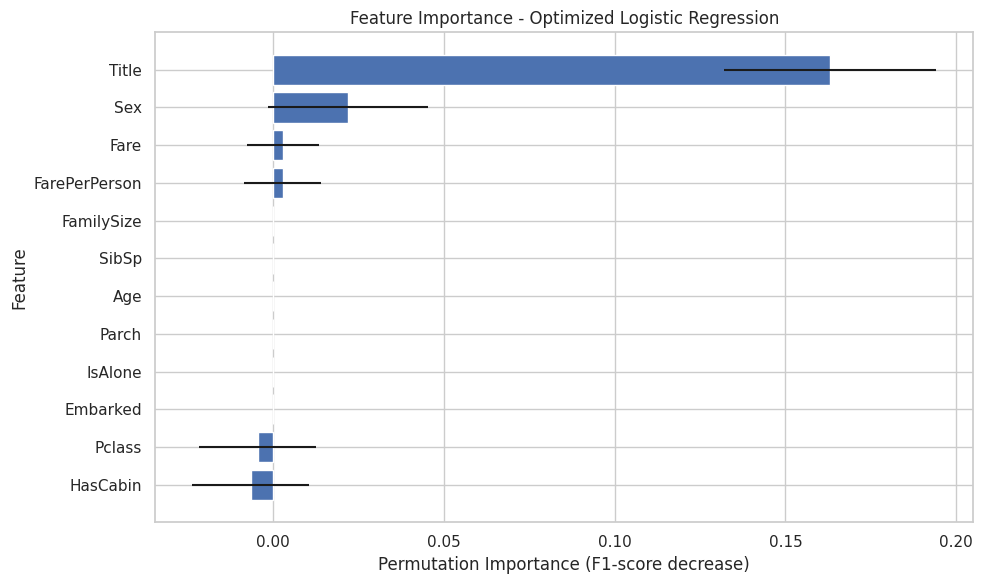

In [14]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Permutation Importance 계산
importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring='f1',
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

# 중요도 데이터프레임 생성
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importance_result.importances_mean,
    'Std': importance_result.importances_std
}).sort_values(by='Importance', ascending=False)

print("===== Feature Importance =====")
display(importance_df.round(4))

# 시각화
plt.figure(figsize=(10, 6))
plt.barh(
    importance_df['Feature'],
    importance_df['Importance'],
    xerr=importance_df['Std']
)
plt.xlabel('Permutation Importance (F1-score decrease)')
plt.ylabel('Feature')
plt.title('Feature Importance - Optimized Logistic Regression')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

#### 8-2. Feature Importance 분석 결과 해석

Permutation Importance 분석 결과, Title 변수의 중요도가 0.1631로 가장 높게 나타났으며, Sex 변수도 0.0219로 상대적으로 높은 중요도를 보였다. 반면 Fare와 FarePerPerson은 각각 0.0030, 0.0028로 낮은 중요도를 나타냈다.

특히 Title 변수는 승객의 이름에서 추출한 호칭 정보로, 성별 및 연령과 관련된 정보를 간접적으로 포함하고 있기 때문에 생존 여부 예측에 중요한 역할을 한 것으로 해석할 수 있다.

한편 FamilySize, SibSp, Age, Parch, IsAlone, Embarked는 중요도가 0으로 나타났다. 이는 해당 변수를 무작위로 섞었을 때 테스트 데이터에서 F1-score의 평균적인 변화가 거의 없었다는 의미이다. 또한 Pclass와 HasCabin은 각각 -0.0045, -0.0065의 음수 중요도를 나타냈다. 이는 해당 변수를 무작위로 섞었을 때 오히려 F1-score가 소폭 높아졌다는 의미이다. 다만 음수 중요도가 해당 변수가 생존 여부에 부정적인 영향을 준다는 뜻은 아니다.

이를 통해 모든 변수가 동일한 수준의 예측 정보를 제공하는 것은 아니며, Title과 Sex 변수가 최적화된 모델의 예측 성능에 상대적으로 크게 기여한다는 점을 확인하였다. 또한 Permutation Importance를 활용하면 모델의 예측에 중요한 변수를 파악하고, 각 변수의 역할을 이해하는 데 도움이 된다는 점을 알 수 있었다.

### STEP 9. SHAP 분석

#### 9-1. SHAP 분석

##### ① SHAP 설치

In [15]:
!pip install shap -q

##### ② SHAP 분석 실행

In [16]:

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# SHAP Analysis - Optimized Logistic Regression
# ==========================================

# 1. 최적 모델 Pipeline에서 각 단계 추출
preprocessor = best_model.named_steps['preprocessor']
selector = best_model.named_steps['feature_selection']
logistic_model = best_model.named_steps['model']

# 2. 학습 데이터와 테스트 데이터 전처리
X_train_transformed = preprocessor.transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

# 3. Feature Selection 적용
X_train_selected = selector.transform(X_train_transformed)
X_test_selected = selector.transform(X_test_transformed)

# 4. 희소 행렬을 일반 배열로 변환
if hasattr(X_train_selected, "toarray"):
    X_train_selected = X_train_selected.toarray()

if hasattr(X_test_selected, "toarray"):
    X_test_selected = X_test_selected.toarray()

# 5. 선택된 특성 이름 추출
all_feature_names = preprocessor.get_feature_names_out()
selected_feature_names = all_feature_names[selector.get_support()]

# 6. DataFrame 변환
X_train_selected = pd.DataFrame(
    X_train_selected,
    columns=selected_feature_names
)

X_test_selected = pd.DataFrame(
    X_test_selected,
    columns=selected_feature_names
)

# 7. SHAP Explainer 생성
background = X_train_selected.sample(
    n=min(100, len(X_train_selected)),
    random_state=42
)

explainer = shap.LinearExplainer(
    logistic_model,
    background
)

# 8. 테스트 데이터 SHAP 값 계산
X_shap = X_test_selected.iloc[
    :min(100, len(X_test_selected))
]

shap_values = explainer(X_shap)

# 9. 결과 확인
print("=" * 60)
print("SHAP ANALYSIS RESULTS")
print("=" * 60)

print("분석 데이터 수:", len(X_shap))
print("전체 전처리 특성 수:", len(all_feature_names))
print("선택된 특성 수:", len(selected_feature_names))
print("모델 입력 특성 수:", logistic_model.coef_.shape[1])

print("\n[Selected Features]")
print(selected_feature_names.tolist())

print("\nSHAP 분석 완료!")


SHAP ANALYSIS RESULTS
분석 데이터 수: 100
전체 전처리 특성 수: 19
선택된 특성 수: 10
모델 입력 특성 수: 10

[Selected Features]
['num__Pclass', 'num__Fare', 'num__IsAlone', 'num__FarePerPerson', 'num__HasCabin', 'cat__Sex_female', 'cat__Sex_male', 'cat__Title_Miss', 'cat__Title_Mr', 'cat__Title_Mrs']

SHAP 분석 완료!


##### ③ SHAP 시각화

###### 1. SHAP Summary Plot

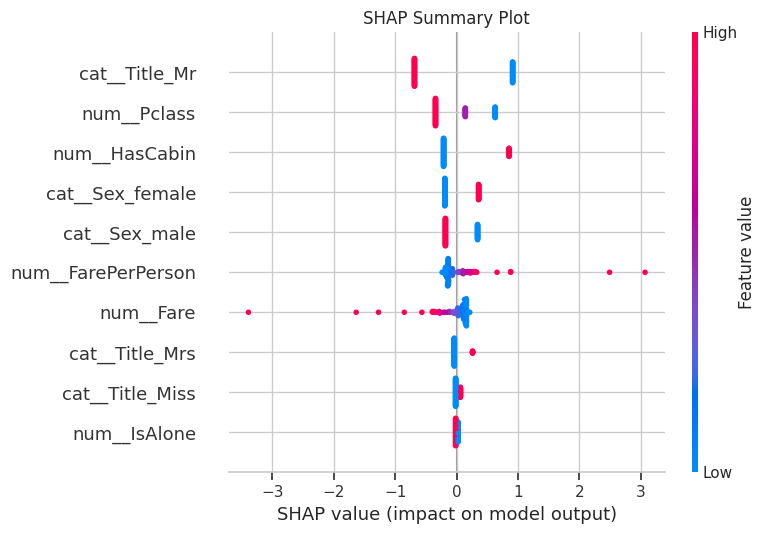

In [17]:
plt.figure()
shap.summary_plot(
    shap_values,
    X_shap,
    show=False
)
plt.title("SHAP Summary Plot")
plt.tight_layout()
plt.show()

###### 2. SHAP Bar Plot

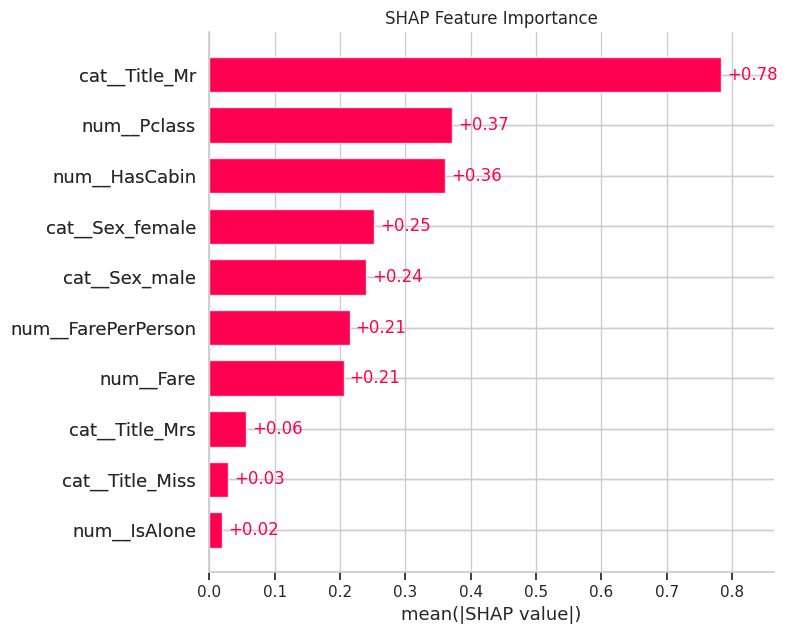

In [18]:
plt.figure()
shap.plots.bar(
    shap_values,
    show=False
)
plt.title("SHAP Feature Importance")
plt.tight_layout()
plt.show()

#### 9-2. SHAP 분석 결과 해석

SHAP 분석을 통해 각 특성이 모델의 생존 예측 결과에 미치는 영향을 확인하였다. Summary Plot과 Bar Plot을 살펴본 결과, Title_Mr 변수가 평균 절대 SHAP 값 약 0.78로 가장 높은 중요도를 나타냈으며, Pclass(약 0.37), HasCabin(약 0.36), Sex_female(약 0.25), Sex_male(약 0.24) 변수도 상대적으로 중요한 특성으로 확인되었다.

특히 Title_Mr 변수는 다른 특성에 비해 모델의 예측 결과에 큰 영향을 주는 것으로 나타났다. Summary Plot에서 Title_Mr 값이 높은 경우(호칭이 Mr인 경우) SHAP 값이 주로 음의 방향으로 분포하였다. 이는 해당 정보가 생존(1) 예측에 부정적인 방향으로 작용하는 경향이 있음을 의미한다. 반대로 Title_Mr 값이 낮은 경우에는 양의 방향으로 작용하는 경향을 확인할 수 있었다.

또한 Pclass와 성별 관련 변수도 예측에 영향을 미치는 것으로 나타났다. 이러한 결과는 앞선 탐색적 데이터 분석에서 확인한 성별 및 객실 등급별 생존율 차이와도 관련이 있는 것으로 해석할 수 있다. HasCabin 변수 역시 상대적으로 높은 중요도를 보였으며, 객실 정보의 유무가 모델의 예측에 활용되었음을 확인하였다.

이를 통해 SHAP 분석은 단순히 변수의 중요도 순위를 확인하는 것을 넘어, 각 특성이 모델의 예측 결과를 어떤 방향으로 변화시키는지 이해하는 데 도움이 된다는 점을 확인하였다. 다만 SHAP 값은 모델의 예측에 대한 기여도를 나타내는 것이며, 변수 간 인과관계를 의미하지는 않는다.

※ 본 SHAP 분석은 전체 실험에서 가장 높은 F1-score를 기록한 모델이 아니라, GridSearchCV를 통해 최적화한 Exp-3 + Feature Selection 모델을 대상으로 수행하였다.


### STEP 10. AutoML 비교 실험


본 단계에서는 Scikit-learn의 RandomizedSearchCV를 활용하여
여러 분류 모델과 하이퍼파라미터 조합을 자동으로 탐색하였다.

Logistic Regression, Random Forest, Extra Trees 모델을 대상으로
5-Fold 교차검증을 수행하고 F1-score를 기준으로 최적 모델을 선정하였다.

모든 모델에 동일한 Exp-1 전처리 파이프라인을 적용하여
모델 종류와 하이퍼파라미터에 따른 성능 차이를 비교하였다.

#### 10-1. AutoML 기반 모델 및 하이퍼파라미터 자동 탐색

In [19]:
# ==========================================
# STEP 10-1. AutoML 모델 및 하이퍼파라미터 자동 탐색
# ==========================================

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline
import pandas as pd

# 1. 교차검증 설정
automl_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 2. 자동 탐색 대상 모델 및 하이퍼파라미터
automl_candidates = [
    (
        'Logistic Regression',
        LogisticRegression(
            max_iter=3000,
            random_state=42
        ),
        {
            'model__C': [0.1, 1, 10],
            'model__class_weight': [None, 'balanced']
        }
    ),
    (
        'Random Forest',
        RandomForestClassifier(
            random_state=42,
            n_jobs=-1
        ),
        {
            'model__n_estimators': [100, 200, 300],
            'model__max_depth': [None, 5, 10],
            'model__min_samples_split': [2, 5],
            'model__class_weight': [None, 'balanced']
        }
    ),
    (
        'Extra Trees',
        ExtraTreesClassifier(
            random_state=42,
            n_jobs=-1
        ),
        {
            'model__n_estimators': [100, 200, 300],
            'model__max_depth': [None, 5, 10],
            'model__min_samples_split': [2, 5],
            'model__class_weight': [None, 'balanced']
        }
    )
]

# 3. 모델별 자동 탐색 실행
automl_searches = {}
automl_results = []

for model_name, estimator, param_grid in automl_candidates:

    print(f"\n===== {model_name} 탐색 시작 =====")

    automl_pipeline = Pipeline([
        ('preprocessor', clone(preprocessor_exp1)),
        ('model', estimator)
    ])

    automl_search = RandomizedSearchCV(
        estimator=automl_pipeline,
        param_distributions=param_grid,
        n_iter=6,
        scoring='f1',
        cv=automl_cv,
        n_jobs=-1,
        random_state=42,
        refit=True
    )

    automl_search.fit(X_train, y_train)

    # 최적 모델 테스트
    best_estimator = automl_search.best_estimator_

    y_pred = best_estimator.predict(X_test)
    y_prob = best_estimator.predict_proba(X_test)[:, 1]

    automl_searches[model_name] = automl_search

    automl_results.append({
        'Model': model_name,
        'Best CV F1-score': automl_search.best_score_,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred, zero_division=0
        ),
        'F1-score': f1_score(
            y_test, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

    print("최적 파라미터:", automl_search.best_params_)
    print("최고 교차검증 F1-score:",
          round(automl_search.best_score_, 4))


# 4. 모델별 성능 비교표
automl_results_df = pd.DataFrame(automl_results)

automl_results_df = automl_results_df.sort_values(
    by='Best CV F1-score',
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("AUTOML MODEL COMPARISON")
print("=" * 70)

display(automl_results_df.round(4))


# 5. 교차검증 F1-score 기준 최적 모델 선정
automl_best_name = automl_results_df.iloc[0]['Model']

automl_best_search = automl_searches[automl_best_name]

automl_best_model = automl_best_search.best_estimator_

print("\n===== AutoML 최종 선택 모델 =====")
print("최적 모델:", automl_best_name)
print("최적 파라미터:", automl_best_search.best_params_)
print("최고 CV F1-score:",
      round(automl_best_search.best_score_, 4))


===== Logistic Regression 탐색 시작 =====
최적 파라미터: {'model__class_weight': None, 'model__C': 1}
최고 교차검증 F1-score: 0.7706

===== Random Forest 탐색 시작 =====
최적 파라미터: {'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__max_depth': 5, 'model__class_weight': 'balanced'}
최고 교차검증 F1-score: 0.7878

===== Extra Trees 탐색 시작 =====
최적 파라미터: {'model__n_estimators': 300, 'model__min_samples_split': 5, 'model__max_depth': 10, 'model__class_weight': 'balanced'}
최고 교차검증 F1-score: 0.7739

AUTOML MODEL COMPARISON


,Model,Best CV F1-score,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.7878,0.8045,0.7297,0.7826,0.7552,0.8476
1,Extra Trees,0.7739,0.7821,0.7027,0.7536,0.7273,0.8484
2,Logistic Regression,0.7706,0.8324,0.8000,0.7536,0.7761,0.8722



===== AutoML 최종 선택 모델 =====
최적 모델: Random Forest
최적 파라미터: {'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__max_depth': 5, 'model__class_weight': 'balanced'}
최고 CV F1-score: 0.7878


#### 10-2. AutoML 실험 결과 분석

RandomizedSearchCV를 활용하여 Logistic Regression, Random Forest, Extra Trees 총 3개 모델의 하이퍼파라미터를 자동으로 탐색하였다. 5-Fold 교차검증 F1-score를 기준으로 비교한 결과, Random Forest가 0.7878로 가장 높은 점수를 기록하여 최적 모델로 선정되었다. 최적 하이퍼파라미터는 n_estimators=300, min_samples_split=2, max_depth=5, class_weight='balanced'였다.

그러나 테스트 데이터 평가에서는 Logistic Regression이 Accuracy 0.8324, F1-score 0.7761, ROC-AUC 0.8722로 가장 높은 성능을 보였다. 반면 Random Forest는 테스트 F1-score 0.7552를 기록하였다. 이는 교차검증에서 가장 높은 점수를 얻은 모델이 반드시 테스트 데이터에서도 가장 높은 성능을 보이는 것은 아니라는 점을 보여준다.

따라서 AutoML의 교차검증 결과와 별도의 테스트 데이터 평가 결과를 함께 고려해야 하며, 모델 선택 시 하나의 평가 지표만으로 판단하지 않는 것이 중요하다.


### STEP 11. 종합 결론 및 한계


#### 11-1. 실험 결과 종합

이번 과제에서는 Titanic 데이터를 활용하여 결측치 처리, 범주형 변수 인코딩, 데이터 스케일링, 파생변수 생성 및 특성 선택을 포함한 Feature Engineering 파이프라인을 구현하였다. 또한 Logistic Regression과 Random Forest 모델을 활용하여 전처리 전략에 따른 예측 성능을 비교하였다.

기본 실험과 세 가지 Feature Engineering 실험 결과를 비교했을 때, Exp-1의 Logistic Regression 모델이 Accuracy 0.8324, F1-score 0.7761, ROC-AUC 0.8722를 기록하여 필수 실험 비교에서 가장 높은 성능을 보였다. Exp-2에서는 Random Forest 모델이 F1-score 0.7407을 기록하였다.

추가로 수행한 Feature Selection 성능 비교에서는 특성 선택이 항상 성능 향상으로 이어지지는 않는다는 점을 확인하였다. 특히 Exp-3의 Logistic Regression 모델은 Feature Selection을 적용하지 않았을 때 F1-score 0.7883을 기록했지만, 적용 후에는 0.6866으로 감소하였다.

GridSearchCV를 적용한 모델의 F1-score는 0.6928로, Feature Selection을 적용한 기존 Exp-3 Logistic Regression 모델의 F1-score 0.6866보다 소폭 향상되었다. 그러나 Feature Selection을 적용하지 않은 Exp-3 모델의 성능에는 미치지 못하였다.

추가로 RandomizedSearchCV 기반의 자동 모델 및 하이퍼파라미터 탐색을 수행하였다. Logistic Regression, Random Forest, Extra Trees를 비교한 결과, 5-Fold 교차검증에서는 Random Forest가 F1-score 0.7878로 가장 높은 성능을 보여 최적 모델로 선정되었다. 다만 테스트 데이터 평가에서는 Logistic Regression이 F1-score 0.7761로 가장 높은 성능을 기록하였다.

이를 통해 전처리와 특성 선택, 하이퍼파라미터 최적화는 모델의 성능에 영향을 주지만, 모든 기법이 항상 성능을 향상시키는 것은 아니라는 점을 확인하였다.

#### 11-2. Feature Engineering 및 특성 중요도 분석

파생변수 생성 과정에서는 FamilySize, IsAlone, FarePerPerson, Title, AgeGroup, HasCabin 변수를 추가하였다. 이를 통해 기존 데이터에 포함된 정보를 재구성하고 승객의 가족 구성, 요금 부담, 호칭 및 객실 정보 등을 모델이 활용할 수 있도록 하였다.

Permutation Importance 분석에서는 Title 변수가 가장 높은 중요도를 보였으며, SHAP 분석에서도 Title_Mr 변수가 중요한 특성으로 확인되었다. 이는 Titanic 데이터에서 승객의 호칭과 성별, 객실 등급 등의 정보가 생존 여부 예측에 중요한 역할을 할 수 있음을 보여준다.

#### 11-3. 실험의 한계 및 개선 방향

이번 실험에는 몇 가지 한계점이 존재한다.

첫째, 기본 모델(Base)은 결측치가 없는 일부 수치형 변수만 사용하였으며, 이 중 FamilySize, IsAlone, FarePerPerson, HasCabin과 같은 파생변수도 포함되어 있다. 반면 Exp-1부터 Exp-3까지는 파생변수와 범주형 변수를 포함한 전체 특성 집합을 활용하였다. 따라서 Base와 다른 실험의 성능 차이를 전처리 기법만의 효과로 해석하기에는 한계가 있다.

둘째, 각 실험에서는 결측치 처리, 인코딩, 스케일링 및 특성 선택 전략이 함께 변경되었다. 따라서 특정 전처리 기법 하나가 성능에 미친 영향을 독립적으로 판단하기는 어렵다. 향후에는 다른 조건을 동일하게 유지하고 하나의 전처리 전략만 변경하는 추가 실험이 필요하다.

셋째, Exp-2에서는 범주형 변수의 정수형 변환을 위해 OrdinalEncoder를 사용하였다. 이 방식은 명목형 범주에 인위적인 순서가 부여될 수 있으므로, 향후에는 다른 인코딩 방식과의 비교를 통해 적절성을 검토할 필요가 있다.

넷째, AgeGroup 파생변수는 생성하였지만 기존 Age 변수와 정보가 중복될 가능성을 고려하여 최종 모델 입력에서는 제외하였다. 또한 하나의 데이터셋과 학습·테스트 분할을 중심으로 실험했기 때문에 다른 데이터에서도 동일한 결과가 나타나는지는 추가 검증이 필요하다.

#### 11-4. 최종 결론

이번 과제를 통해 Feature Engineering은 단순히 새로운 변수를 생성하는 작업이 아니라, 데이터의 특성과 모델의 학습 방식에 맞춰 결측치 처리, 인코딩, 스케일링 및 특성 선택을 종합적으로 설계하는 과정이라는 점을 이해할 수 있었다.

또한 동일한 데이터라도 전처리 방법과 모델 종류에 따라 예측 성능이 달라질 수 있으며, 복잡한 전처리 기법이나 특성 선택을 적용한다고 해서 반드시 좋은 결과가 나타나는 것은 아니라는 점을 확인하였다.

결과적으로 데이터의 특성을 먼저 파악하고, 여러 전처리 전략과 모델을 비교한 뒤 성능 지표 및 특성 중요도 분석을 바탕으로 적절한 파이프라인을 선택하는 것이 중요하다는 결론을 얻었다.

#### 11-5. 과제 핵심 질문에 대한 답변

##### 1. 어떤 전처리 전략이 가장 효과적이었는가?

필수 실험 결과에서는 Mean Imputation, One-Hot Encoding, StandardScaler를 적용한 Exp-1의 Logistic Regression 모델이 F1-score 0.7761, ROC-AUC 0.8722로 가장 높은 성능을 보였다. 다만 이는 해당 데이터와 모델, 실험 조건에서의 결과이며 모든 데이터에 동일하게 적용되는 것은 아니다.

##### 2. One-Hot Encoding이 항상 좋은가?

Exp-1과 Exp-3에서 One-Hot Encoding을 사용했지만 성능은 서로 다르게 나타났다. 따라서 One-Hot Encoding 자체가 항상 가장 좋은 성능을 보장한다고 할 수 없다. 또한 이번 실험에서는 여러 전처리 조건이 함께 변경되었으므로 인코딩 방식만의 영향을 독립적으로 판단하기는 어렵다.

##### 3. Feature Selection이 과적합 감소에 기여했는가?

Feature Selection 적용 전후의 테스트 성능을 비교한 결과, 대부분의 실험에서 F1-score가 감소했으며 Exp-2 Random Forest에서만 소폭 향상되었다. 다만 학습 데이터와 테스트 데이터의 성능 차이를 별도로 분석하지 않았으므로 과적합 감소 여부를 직접적으로 판단하기는 어렵다.

##### 4. 스케일링은 모델별로 어떤 영향을 미쳤는가?

StandardScaler, MinMaxScaler, RobustScaler를 적용한 실험에서 모델별 성능 차이가 나타났다. 그러나 결측치 처리와 인코딩, Feature Selection도 함께 변경되었기 때문에 스케일링 하나만의 효과를 분리해서 설명할 수는 없다.

##### 5. Feature Engineering이 실제 성능 향상에 얼마나 기여했는가?

FamilySize, IsAlone, FarePerPerson, Title, AgeGroup, HasCabin 등 6개의 파생변수를 생성하여 모델 입력에 활용하거나 분석하였다. 특히 Title은 Permutation Importance와 SHAP 분석에서 중요한 특성으로 확인되었다. 다만 파생변수 생성 전후를 동일한 조건으로 비교한 별도의 실험은 수행하지 않았으므로, 파생변수 생성만으로 성능이 얼마나 향상되었는지 수치로 분리해 판단하기는 어렵다.